In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk # library for biosignal processing
import pywt # For wavelet transforms
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import warnings
warnings.filterwarnings('ignore')
import os

In [2]:
base_path = r"C:\Users\manal\OneDrive\Desktop"
DATA_PATH = os.path.join(base_path, "WESAD")
SUBJECT_ID = 'S16' # Example subject ID to process
ECG_SAMPLING_RATE_RESP = 700 # Hz (from WESAD documentation for RespiBAN ECG)
LABEL_SAMPLING_RATE = 700 # Hz (from WESAD documentation for labels)
HRV_INTERPOLATION_RATE = 4 # Hz (Common for HRV spectral analysis, as per RHRV example in the wavelet paper)
WINDOW_SIZE_SEC = 300 # 5 minutes for rolling feature aggregation
WINDOW_OVERLAP_SEC = 60 # 1 minute overlap for smooth features

In [3]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('deep')

print(f"--- Preprocessing for Subject: {SUBJECT_ID} ---")

--- Preprocessing for Subject: S16 ---


In [4]:
file_path = os.path.join(DATA_PATH, "S16", "S16.pkl")  # Example file inside WESAD


In [5]:
print(f"Loading data for {SUBJECT_ID} from {DATA_PATH}\{SUBJECT_ID}\{SUBJECT_ID}.pkl...")
try:
    with open(f"{DATA_PATH}\{SUBJECT_ID}\{SUBJECT_ID}.pkl", 'rb') as f:
        data = pickle.load(f, encoding='latin1')
    print("Data loaded successfully.")
except FileNotFoundError:
    print(f"Error: {DATA_PATH}\{SUBJECT_ID}\{SUBJECT_ID}.pkl not found. Please check DATA_PATH.")
    exit()


Loading data for S16 from C:\Users\manal\OneDrive\Desktop\WESAD\S16\S16.pkl...
Data loaded successfully.


In [6]:
print("\n--- Data Structure Overview ---")
print(f"Keys in loaded data: {data.keys()}")

signal_data = data['signal']
print(f"Keys in signal data: {signal_data.keys()}")

chest_data = signal_data['chest']
print(f"Keys in chest data: {chest_data.keys()}")


--- Data Structure Overview ---
Keys in loaded data: dict_keys(['signal', 'label', 'subject'])
Keys in signal data: dict_keys(['chest', 'wrist'])
Keys in chest data: dict_keys(['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'])


In [7]:
ecg_signal = chest_data['ECG']
labels = data['label']

print(f"ECG signal shape: {ecg_signal.shape}")
print(f"Labels shape: {labels.shape}")


ECG signal shape: (3941700, 1)
Labels shape: (3941700,)


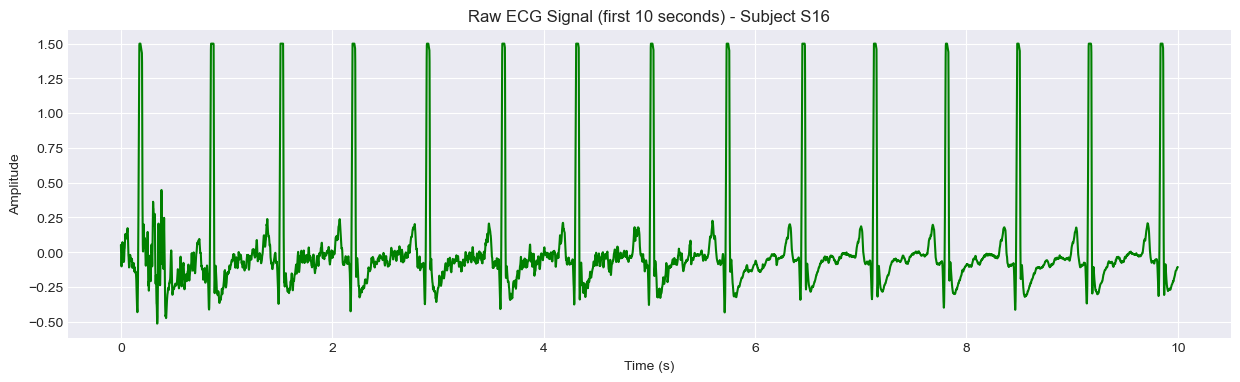

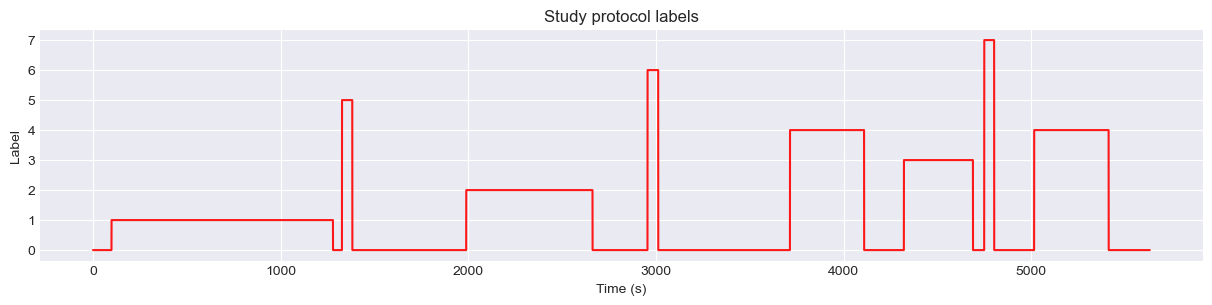

In [8]:
plt.figure(figsize=(15, 4))
plt.plot(np.arange(len(ecg_signal[:ECG_SAMPLING_RATE_RESP*10])) / ECG_SAMPLING_RATE_RESP, 
         ecg_signal[:ECG_SAMPLING_RATE_RESP*10],color='g')
plt.title(f'Raw ECG Signal (first 10 seconds) - Subject {SUBJECT_ID}')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

plt.figure(figsize=(15, 3))
plt.plot(np.arange(len(labels)) / LABEL_SAMPLING_RATE, labels, alpha=0.9,color='r')
plt.title('Study protocol labels')
plt.xlabel('Time (s)')
plt.ylabel('Label')
plt.show()

In [9]:
print("\n--- II. RR Interval Extraction from ECG ---")

print(f"Processing ECG signal of length {len(ecg_signal)} samples at {ECG_SAMPLING_RATE_RESP} Hz...")

# Initialize variables to safe defaults
rr_df = pd.DataFrame()
rpeaks_indices = np.array([])

try:
    # Clean ECG signal
    print("Cleaning ECG signal...")
    cleaned_ecg = nk.ecg_clean(ecg_signal, sampling_rate=ECG_SAMPLING_RATE_RESP)

    # Detect R-peaks
    print("Detecting R-peaks...")
    _, rpeaks = nk.ecg_peaks(cleaned_ecg, sampling_rate=ECG_SAMPLING_RATE_RESP)

    # Extract R-peak indices
    rpeaks_indices = rpeaks['ECG_R_Peaks']

    print(f"Detected {len(rpeaks_indices)} R-peaks.")

    if len(rpeaks_indices) > 1:
        # Compute RR intervals in ms
        rr_intervals_ms = np.diff(rpeaks_indices) / ECG_SAMPLING_RATE_RESP * 1000
        rr_times_sec = rpeaks_indices[1:] / ECG_SAMPLING_RATE_RESP

        rr_df = pd.DataFrame({'Time_sec': rr_times_sec, 'RR_ms': rr_intervals_ms})

        print(f"Calculated {len(rr_intervals_ms)} RR intervals.")
        print(f"First 5 RR intervals:\n{rr_df.head()}")
    else:
        print("Too few R-peaks to compute RR intervals.")

except Exception as e:
    print(f"An error occurred: {e}")


--- II. RR Interval Extraction from ECG ---
Processing ECG signal of length 3941700 samples at 700 Hz...
Cleaning ECG signal...
Detecting R-peaks...
Detected 8042 R-peaks.
Calculated 8041 RR intervals.
First 5 RR intervals:
   Time_sec       RR_ms
0  1.521429  658.571429
1  2.202857  681.428571
2  2.905714  702.857143
3  3.620000  714.285714
4  4.317143  697.142857


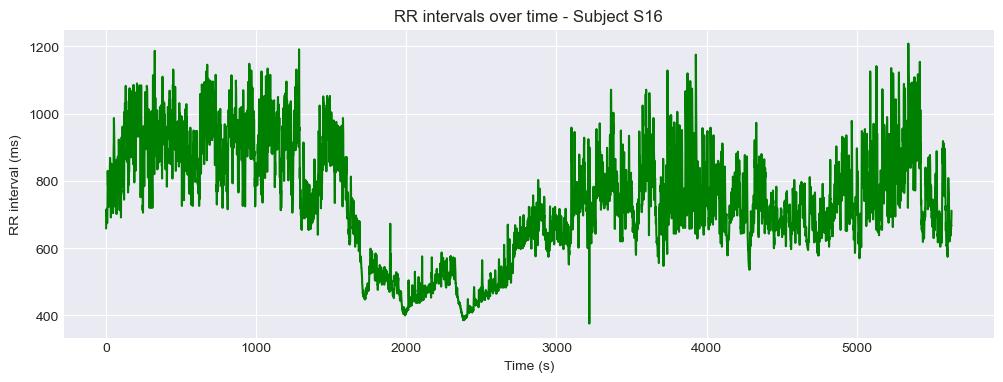

In [10]:
plt.figure(figsize=(12,4))
plt.plot(rr_df['Time_sec'], rr_df['RR_ms'],color='g')
plt.title(f'RR intervals over time - Subject {SUBJECT_ID}')
plt.xlabel('Time (s)')
plt.ylabel('RR interval (ms)')
plt.show()

In [11]:
print("\n--- Sliding window HRV feature extraction ---")

WINDOW_SIZE_SEC = 120  # try 2 minutes
WINDOW_STEP_SEC = 60   # 1-minute overlap
window_size_samples = WINDOW_SIZE_SEC * ECG_SAMPLING_RATE_RESP
step_size_samples = WINDOW_STEP_SEC * ECG_SAMPLING_RATE_RESP

print(f"Window size: {window_size_samples} samples")
print(f"Step size: {step_size_samples} samples")

hrv_features_list = []

for start in range(0, len(ecg_signal) - window_size_samples, step_size_samples):
    end = start + window_size_samples
    window_center_sec = (start + end) / 2 / ECG_SAMPLING_RATE_RESP
    
    # Find R-peaks in this window
    peaks_in_window = rpeaks_indices[(rpeaks_indices >= start) & (rpeaks_indices < end)] - start
    
    if len(peaks_in_window) > 2:
        # Build peaks DataFrame expected by nk.hrv
        peaks_df = pd.DataFrame({"ECG_R_Peaks": np.zeros(window_size_samples, dtype=bool)})
        peaks_df.loc[peaks_in_window, "ECG_R_Peaks"] = True
        
        try:
            hrv = nk.hrv(peaks_df, sampling_rate=ECG_SAMPLING_RATE_RESP, show=False)
            hrv_row = hrv.iloc[0].to_dict()
            
            # Add time and label
            window_labels = labels[start:end]
            most_common_label = np.bincount(window_labels).argmax()
            hrv_row["Time"] = window_center_sec
            hrv_row["Label"] = most_common_label
            
            hrv_features_list.append(hrv_row)
            
        except Exception as e:
            print(f"Error computing HRV in window starting at {start}: {e}")
    else:
        print(f"Too few peaks in window starting at {start}, skipping.")

# Convert to DataFrame
df_features = pd.DataFrame(hrv_features_list)
print("\n--- HRV Feature Table ---")
print("Shape:", df_features.shape)
print("Columns:", df_features.columns)


--- Sliding window HRV feature extraction ---
Window size: 84000 samples
Step size: 42000 samples

--- HRV Feature Table ---
Shape: (92, 93)
Columns: Index(['HRV_MeanNN', 'HRV_SDNN', 'HRV_SDANN1', 'HRV_SDNNI1', 'HRV_SDANN2',
       'HRV_SDNNI2', 'HRV_SDANN5', 'HRV_SDNNI5', 'HRV_RMSSD', 'HRV_SDSD',
       'HRV_CVNN', 'HRV_CVSD', 'HRV_MedianNN', 'HRV_MadNN', 'HRV_MCVNN',
       'HRV_IQRNN', 'HRV_SDRMSSD', 'HRV_Prc20NN', 'HRV_Prc80NN', 'HRV_pNN50',
       'HRV_pNN20', 'HRV_MinNN', 'HRV_MaxNN', 'HRV_HTI', 'HRV_TINN', 'HRV_ULF',
       'HRV_VLF', 'HRV_LF', 'HRV_HF', 'HRV_VHF', 'HRV_TP', 'HRV_LFHF',
       'HRV_LFn', 'HRV_HFn', 'HRV_LnHF', 'HRV_SD1', 'HRV_SD2', 'HRV_SD1SD2',
       'HRV_S', 'HRV_CSI', 'HRV_CVI', 'HRV_CSI_Modified', 'HRV_PIP',
       'HRV_IALS', 'HRV_PSS', 'HRV_PAS', 'HRV_GI', 'HRV_SI', 'HRV_AI',
       'HRV_PI', 'HRV_C1d', 'HRV_C1a', 'HRV_SD1d', 'HRV_SD1a', 'HRV_C2d',
       'HRV_C2a', 'HRV_SD2d', 'HRV_SD2a', 'HRV_Cd', 'HRV_Ca', 'HRV_SDNNd',
       'HRV_SDNNa', 'HRV_DFA_alp

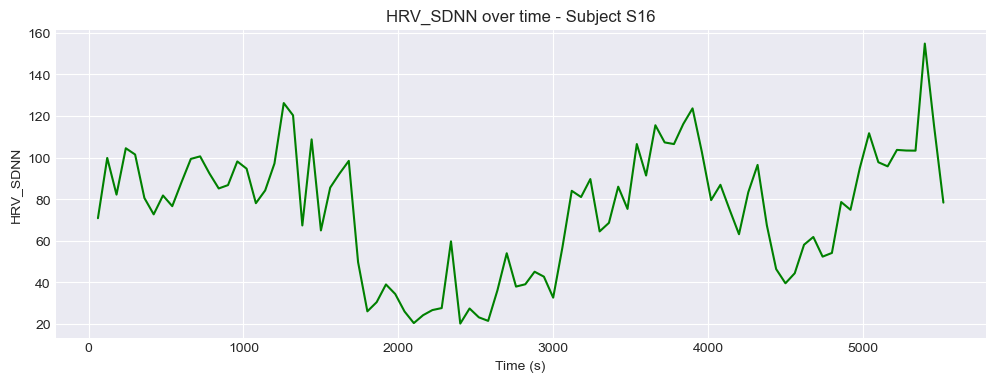

In [12]:
plt.figure(figsize=(12,4))
plt.plot(df_features['Time'], df_features['HRV_SDNN'],color='g')
plt.title(f'HRV_SDNN over time - Subject {SUBJECT_ID}')
plt.xlabel('Time (s)')
plt.ylabel('HRV_SDNN')
plt.show()

In [13]:
import pickle
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import neurokit2 as nk
import torch

import torch.nn as nn
import torch
torch.manual_seed(2)

In [14]:
base_path = r"C:\Users\manal\OneDrive\Desktop"
DATA_PATH = os.path.join(base_path, "WESAD")
subject_ids = ['S2','S3','S4','S5','S6','S7','S8','S9','S10','S11','S13','S14','S15','S16','S17']
ECG_SAMPLING_RATE_RESP = 700
WINDOW_SIZE_SEC = 120
WINDOW_STEP_SEC = 60
window_size_samples = WINDOW_SIZE_SEC * ECG_SAMPLING_RATE_RESP
step_size_samples = WINDOW_STEP_SEC * ECG_SAMPLING_RATE_RESP

# Store all detailed results
all_results = []

def process_subject(subject_id):
    print(f"\n=== Processing {subject_id} ===")
    try:
        with open(f"{DATA_PATH}\{SUBJECT_ID}\{SUBJECT_ID}.pkl", 'rb') as f:
            data = pickle.load(f, encoding='latin1')
    except Exception as e:
        print(f"Could not load data for {subject_id}: {e}")
        return None
    
    # Extract ECG and labels
    ecg_signal = data['signal']['chest']['ECG']
    labels = data['label']
    
    # Clean ECG & find R-peaks
    cleaned_ecg = nk.ecg_clean(ecg_signal, sampling_rate=ECG_SAMPLING_RATE_RESP)
    _, rpeaks = nk.ecg_peaks(cleaned_ecg, sampling_rate=ECG_SAMPLING_RATE_RESP)
    rpeaks_indices = rpeaks['ECG_R_Peaks']

    # Sliding window HRV features
    hrv_features_list = []
    for start in range(0, len(ecg_signal) - window_size_samples, step_size_samples):
        end = start + window_size_samples
        window_center_sec = (start + end) / 2 / ECG_SAMPLING_RATE_RESP
        
        peaks_in_window = rpeaks_indices[(rpeaks_indices >= start) & (rpeaks_indices < end)] - start
        
        if len(peaks_in_window) > 2:
            peaks_df = pd.DataFrame({"ECG_R_Peaks": np.zeros(window_size_samples, dtype=bool)})
            peaks_df.loc[peaks_in_window, "ECG_R_Peaks"] = True
            try:
                hrv = nk.hrv(peaks_df, sampling_rate=ECG_SAMPLING_RATE_RESP, show=False)
                hrv_row = hrv.iloc[0].to_dict()
                window_labels = labels[start:end]
                most_common_label = np.bincount(window_labels).argmax()
                hrv_row["Time"] = window_center_sec
                hrv_row["Label"] = most_common_label
                hrv_features_list.append(hrv_row)
            except Exception as e:
                continue

    if not hrv_features_list:
        print(f"No HRV features extracted for {subject_id}")
        return None

    df_features = pd.DataFrame(hrv_features_list)
    df_features["Label"] = df_features["Label"].map(lambda x: x if x in [0,1,2,3] else 0)
    df_features = df_features[df_features["Label"].isin([1,2,3])]
    df_features["Label"] = df_features["Label"].replace([1,2,3],[0,1,2])

    df_features = df_features.fillna(df_features.median())
    nan_counts = df_features.isna().sum()
    df_features = df_features.drop(columns=nan_counts[nan_counts > (0.2*len(df_features))].index)
    
    X = df_features.drop(columns=["Time", "Label"])
    y = df_features["Label"]

    if len(y.unique()) < 2 or len(y) < 10:
        print(f"Not enough data to train for {subject_id}")
        return None

    return X,y

In [15]:
# Process all subjects

X = []
Y = []
for subject_id in tqdm(subject_ids):
    x,y = process_subject(subject_id)

    X.append(x)
    Y.append(y)

  0%|          | 0/15 [00:00<?, ?it/s]


=== Processing S2 ===

=== Processing S3 ===

=== Processing S4 ===

=== Processing S5 ===

=== Processing S6 ===

=== Processing S7 ===

=== Processing S8 ===

=== Processing S9 ===

=== Processing S10 ===

=== Processing S11 ===

=== Processing S13 ===

=== Processing S14 ===

=== Processing S15 ===

=== Processing S16 ===

=== Processing S17 ===


In [16]:
X = pd.concat(X)
y = pd.concat(Y)

X.reset_index(drop=True,inplace=True)
y.reset_index(drop=True,inplace=True)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

In [17]:
x_train = X_train.reshape(-1, X_train.shape[1]).astype('float32')
y_train = y_train.to_numpy()

X_test = X_test.reshape(-1, X_test.shape[1]).astype('float32')

In [18]:
X_test = torch.from_numpy(X_test)
y_test = torch.from_numpy(y_test.to_numpy()).long()

In [19]:
from torch.utils.data import Dataset, DataLoader
class Data(Dataset):
    def __init__(self):
        self.x=torch.from_numpy(x_train)
        self.y=torch.from_numpy(y_train)
        self.len=self.x.shape[0]
    def __getitem__(self,index):      
        return self.x[index], self.y[index]
    def __len__(self):
        return self.len

In [20]:
data_set=Data()
trainloader=DataLoader(dataset=data_set,batch_size=64)

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in, 128)
        self.linear2 = nn.Linear(128, 64)
        self.linear3 = nn.Linear(64, 32)
        self.linear4 = nn.Linear(32, D_out)

    def forward(self, x):
        # Use ReLU instead of sigmoid for hidden layers
        x = F.relu(self.linear1(x))
        x = F.relu(self.linear2(x))
        x = F.relu(self.linear3(x))
        
        # Output logits (no activation here)
        x = self.linear4(x)
        return x


In [22]:
input_dim= 83    # how many Variables are in the dataset
hidden_dim = 25 # hidden layers
output_dim= 3    # number of classes
input_dim

83

In [23]:
# Instantiate model
model=Net(input_dim,hidden_dim,output_dim)

In [24]:
criterion=nn.CrossEntropyLoss()
learning_rate=0.1
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate)

In [25]:
n_epochs=2000
loss_list=[]

#n_epochs
for epoch in range(n_epochs):
    for x, y in trainloader:
      
        #clear gradient 
        optimizer.zero_grad()
        #make a prediction 
        z=model(x)
        loss=criterion(z,y)
        # calculate gradients of parameters 
        loss.backward()
        # update parameters 
        optimizer.step()
        
        loss_list.append(loss.data)
        
        print('epoch {}, loss {}'.format(epoch, loss.item()))

epoch 0, loss 1.1273446083068848
epoch 0, loss 46.16899108886719
epoch 0, loss 124.227294921875
epoch 0, loss 8.218417167663574
epoch 0, loss 0.8829781413078308
epoch 0, loss 0.9645206928253174
epoch 0, loss 0.8696678876876831
epoch 1, loss 0.12690138816833496
epoch 1, loss 1.9223822355270386
epoch 1, loss 6.2442145347595215
epoch 1, loss 4.212685585021973
epoch 1, loss 12.062682151794434
epoch 1, loss 3.4643607139587402
epoch 1, loss 2.0153369903564453
epoch 2, loss 5.211069107055664
epoch 2, loss 6.456456503656227e-06
epoch 2, loss 5.569277163886e-07
epoch 2, loss 3.725290076417309e-09
epoch 2, loss 0.26094019412994385
epoch 2, loss 2.6989258913090453e-05
epoch 2, loss 6.818007946014404
epoch 3, loss 3.7488698959350586
epoch 3, loss 1.2832434177398682
epoch 3, loss 3.2110064029693604
epoch 3, loss 0.008558383211493492
epoch 3, loss 4.1670637130737305
epoch 3, loss 0.0018417703686282039
epoch 3, loss 0.47230520844459534
epoch 4, loss 1.4118980169296265
epoch 4, loss 0.0
epoch 4, loss 

In [ ]:
z=model(X_test)
y_pred=torch.max(z.data,1)

In [ ]:
y_predicted = y_pred.indices
print(classification_report(y_test, y_predicted))

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_predicted)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['baseline','stress','amusement'], 
            yticklabels=['baseline','stress','amusement'])

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()